# Esperimento M3 - Gradini di corrente lunghi: un solo spike?

**Domanda:** se inietto una corrente **costante e lunga**, il neurone MNTB fa **un solo spike** all'inizio
(come i neuroni veri) oppure spara di continuo?

Nei neuroni MNTB veri la risposta tipica è **un solo spike** (o pochissimi) all'inizio del gradino:
è il lavoro di **I_LT** (Kv1, il "buttafuori"), che si apre appena la tensione sale e impedisce altri spike.

Riproduce:
- **Macica 2003, Figura 7b**: gradini di 100 ms da −50 a +150 pA, prima e dopo PMA → un solo spike in entrambi i casi;
- **Wang 1998, Figura 1A-B**: con DTX (blocco di I_LT) il neurone fa **molti spike** durante il gradino.

| Condizione | Come la simulo | Atteso |
|---|---|---|
| Controllo | tutti i parametri come nel modello compilato nella prima cella | un solo spike all'inizio |
| PMA | `g_Kv3` del modello ridotto di un terzo (come Macica: 150 → 100 nS) | un solo spike (la PMA non cambia I_LT né la soglia) |
| DTX | `g_LT` = 0 nS, il resto come nel modello | molti spike durante il gradino |

**Nota:** nessun parametro è scritto a mano nel codice: le condizioni vengono calcolate dai valori del file
`.nestml` compilato nella prima cella, quindi cambiando modello l'esperimento si adatta da solo.

**Stimolo:** gradini di 100 ms di −50, 0, +50, +100, +150 pA (come Macica Fig. 7b).


In [1]:
# ============================================================
# 0. SETUP: import, compilazione del modello, funzione di simulazione
# ============================================================

import os
os.environ["PYNEST_QUIET"] = "1"    # nasconde il banner di NEST

import numpy as np
import matplotlib.pyplot as plt
import nest
nest.set_verbosity("M_WARNING")    # mostra solo avvisi ed errori di NEST, non i messaggi informativi
import pynestml
from pynestml.codegeneration.nest_code_generator_utils import NESTCodeGeneratorUtils

print("NEST  :", nest.__version__)
print("NESTML:", pynestml.__version__)

# Genera il codice C++, lo compila e lo carica in NEST (circa 1 minuto)
# Passo il NOME del file e non il suo contenuto: se riceve il testo del modello, NESTML
# riscrive mntb_hh_kv3_neuron.nestml nella cartella corrente aggiungendo ogni volta
# una riga vuota in fondo (pynestml nest_code_generator_utils.py, righe 101-104).
wt_module, wt_model = NESTCodeGeneratorUtils.generate_code_for("mntb_hh_kv3_neuron_prova.nestml")
print("Modello:", wt_model)

dt = 0.01   # ms - passo di simulazione


def run_simulation(amplitude_times, amplitude_values, sim_time, params=None):
    # Simula il neurone con una corrente a gradini e restituisce tempi (ms) e V_m (mV).
    #   amplitude_times  : istanti (ms) in cui la corrente cambia valore
    #   amplitude_values : valore della corrente (pA) a partire da ciascun istante
    #   sim_time         : durata totale della simulazione (ms)
    #   params           : parametri del neurone da cambiare, es. {"g_Kv3": 0.0}
    nest.ResetKernel()
    nest.SetKernelStatus({"resolution": dt})
    nest.Install(wt_module)

    neuron = nest.Create(wt_model, 1, params=params or {})

    stimulus = nest.Create(
        "step_current_generator",
        params={"amplitude_times": amplitude_times,
                "amplitude_values": amplitude_values},
    )
    multimeter = nest.Create("multimeter", params={"record_from": ["V_m"], "interval": dt})

    # ritardo minimo (dt) invece del default di 1 ms
    nest.Connect(stimulus, neuron, syn_spec={"delay": dt})
    nest.Connect(multimeter, neuron)

    nest.Simulate(sim_time)

    events = multimeter.get("events")
    order = np.argsort(events["times"])
    return events["times"][order], events["V_m"][order]


NEST  : 3.9.0
NESTML: 8.2.0


[ODE-toolbox] WARNING:Not preserving expression for variable "refr_t" as it is solved by propagator solver


Modello: mntb_hh_kv3_neuron_prova_nestml


Modello: mntb_hh_kv3_neuron_prova_nestml  |  g_Kv3 = 150 nS, g_LT = 30 nS, g_L = 4 nS


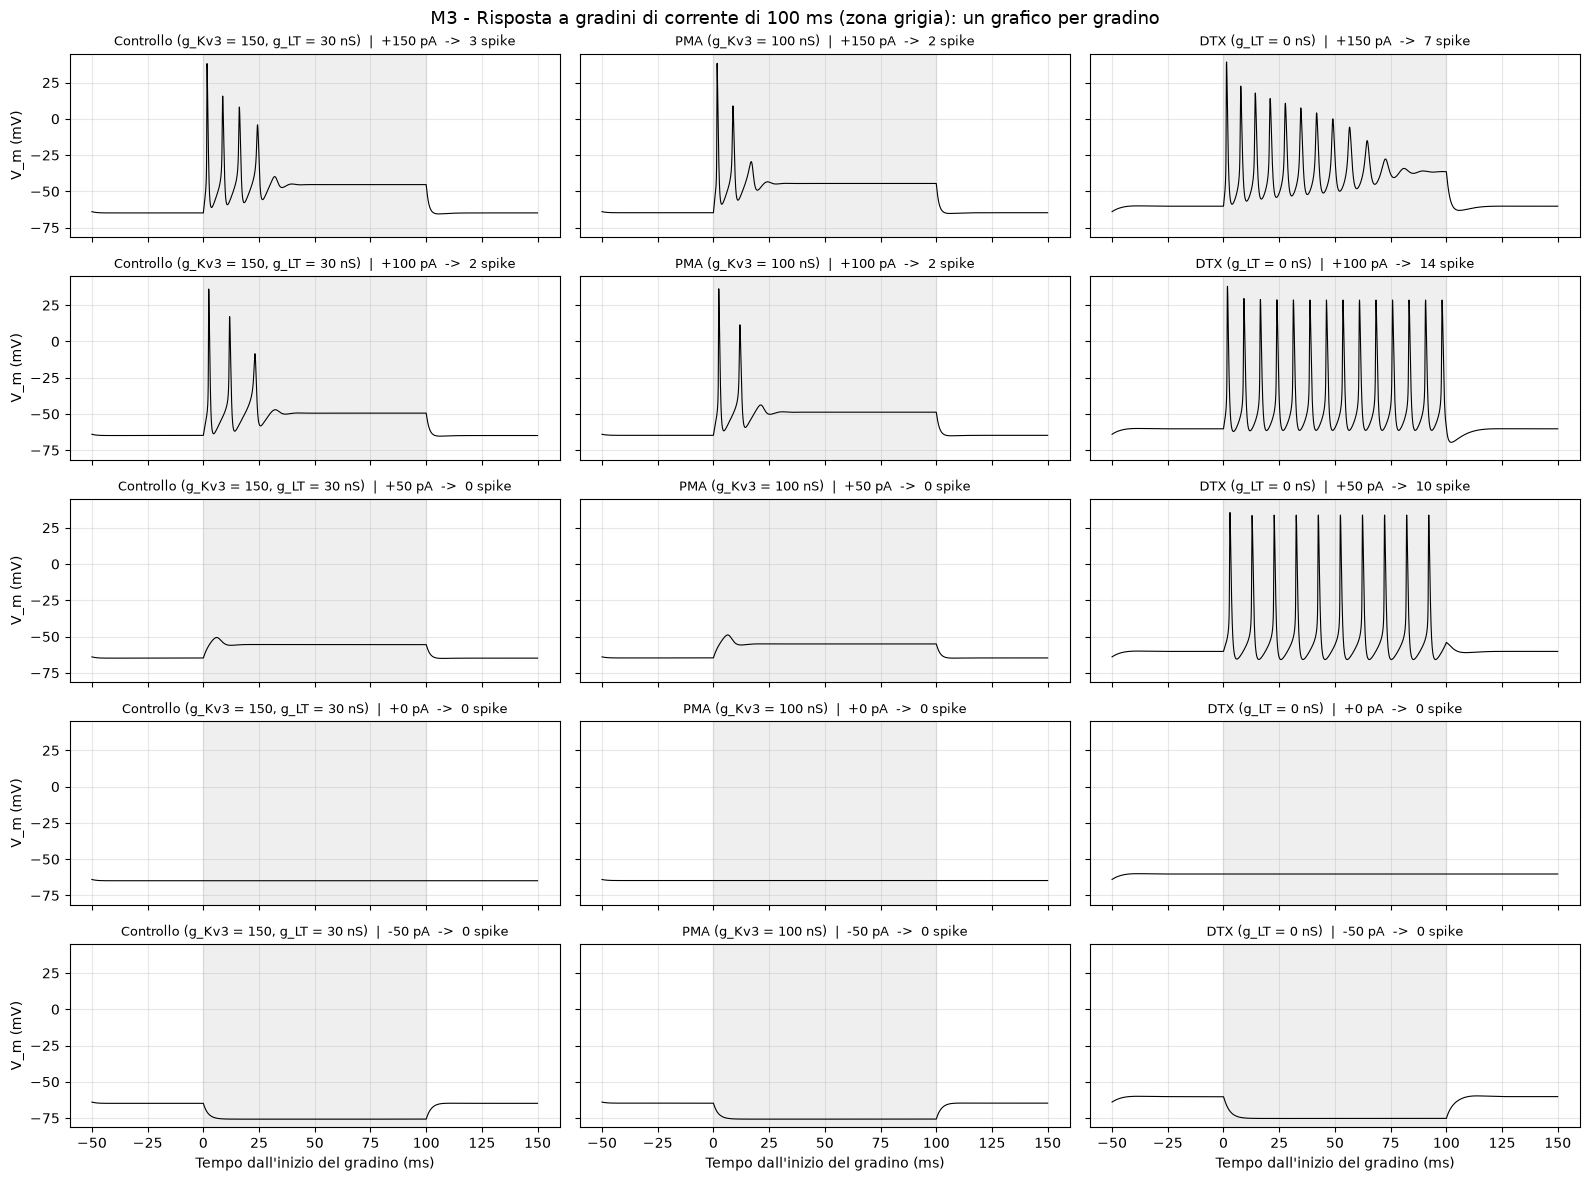

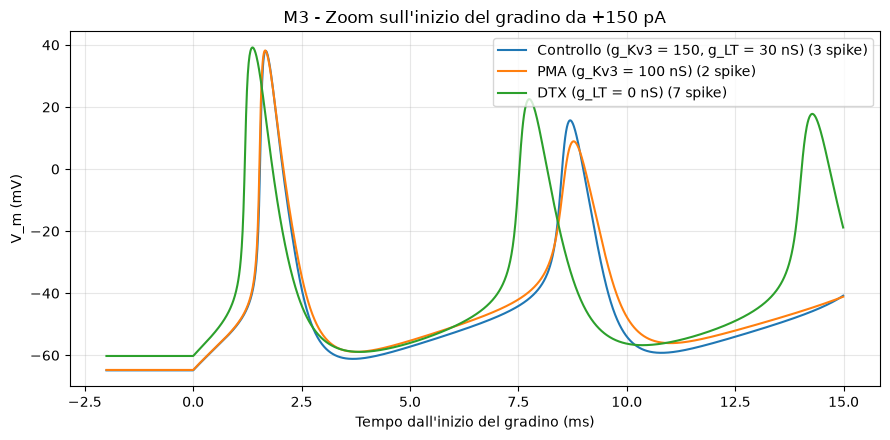

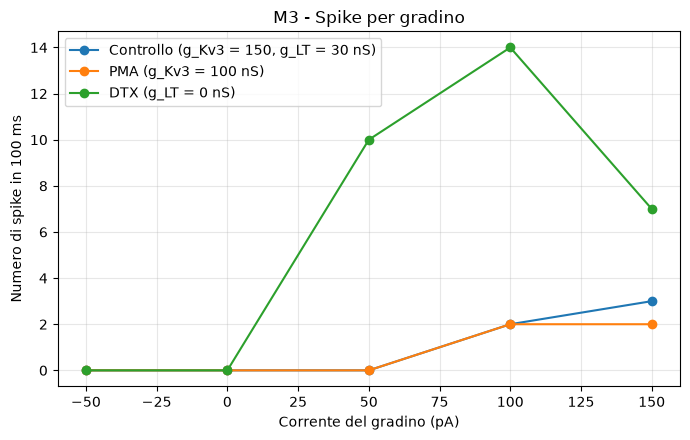

M3 - RIEPILOGO: numero di spike durante il gradino (V a fine gradino in mV)
  I (pA)Controllo (g_Kv3 = 150, g_LT = 30 nS)      PMA (g_Kv3 = 100 nS)         DTX (g_LT = 0 nS)
     -50              0 (-75.8 mV)              0 (-75.8 mV)              0 (-75.3 mV)
       0              0 (-64.9 mV)              0 (-64.7 mV)              0 (-60.2 mV)
      50              0 (-55.5 mV)              0 (-55.1 mV)             10 (-50.7 mV)
     100              2 (-49.4 mV)              2 (-48.8 mV)             14 (-43.1 mV)
     150              3 (-45.3 mV)              2 (-44.6 mV)              7 (-36.3 mV)
--------------------------------------------------------------------------
Atteso: Controllo e PMA -> 1 spike all'inizio (Macica Fig. 7b); DTX -> molti spike (Wang Fig. 1B).


In [2]:
# ============================================================
# M3 - Gradini di corrente lunghi (100 ms)
# ============================================================

step_amps = [-50.0, 0.0, 50.0, 100.0, 150.0]   # pA
t_settle = 50.0                                # ms - attesa iniziale
step_dur = 100.0                               # ms
sim_time = t_settle + step_dur + 50.0

# Parametri letti dal MODELLO compilato nella prima cella (nessun valore scritto a mano):
# cambiando il file .nestml, le condizioni si adattano da sole.
nest.ResetKernel()
nest.Install(wt_module)
model_defaults = nest.GetDefaults(wt_model)
g_Kv3_model = model_defaults["g_Kv3"]
g_LT_model = model_defaults["g_LT"]
print(f"Modello: {wt_model}  |  g_Kv3 = {g_Kv3_model:g} nS, g_LT = {g_LT_model:g} nS, g_L = {model_defaults['g_L']:g} nS")

pma_factor = 100.0 / 150.0     # PMA: Kv3 ridotto di un terzo, come in Macica (150 -> 100 nS)

conditions = {
    # Controllo: nessun parametro cambiato, tutto come nel modello
    f"Controllo (g_Kv3 = {g_Kv3_model:g}, g_LT = {g_LT_model:g} nS)": {},
    # PMA: solo g_Kv3 ridotto di un terzo rispetto al modello
    f"PMA (g_Kv3 = {g_Kv3_model * pma_factor:.0f} nS)": {"g_Kv3": g_Kv3_model * pma_factor},
    # DTX: solo I_LT bloccata
    "DTX (g_LT = 0 nS)": {"g_LT": 0.0},
}
spike_threshold = 0.0   # mV - conto uno spike ogni volta che V supera 0 mV salendo


def count_spikes(t, V, t_start, t_end):
    # Conta gli attraversamenti di 0 mV verso l'alto tra t_start e t_end
    m = (t >= t_start) & (t <= t_end)
    v = V[m]
    return int(np.sum((v[:-1] < spike_threshold) & (v[1:] >= spike_threshold)))


results_M3 = {}
for label, params in conditions.items():
    for amp in step_amps:
        t, V = run_simulation([t_settle, t_settle + step_dur], [amp, 0.0], sim_time, params=params)
        t_on = t_settle + dt
        n_sp = count_spikes(t, V, t_on, t_on + step_dur)
        V_late = np.mean(V[(t >= t_on + step_dur - 20.0) & (t < t_on + step_dur)])
        results_M3[(label, amp)] = {"t": t, "V": V, "t_on": t_on, "n_spikes": n_sp, "V_late": V_late}

# ------------------------------------------------------------
# Figura 1 - Un grafico per ogni gradino, come Macica Fig. 7b / Wang Fig. 1A-B
# righe = corrente del gradino (in alto la piu' forte, come nei paper), colonne = condizioni
# ------------------------------------------------------------
rows = list(reversed(step_amps))
fig, axes = plt.subplots(len(rows), len(conditions), figsize=(16, 2.4 * len(rows)),
                         sharex=True, sharey=True)
for col, label in enumerate(conditions):
    for row, amp in enumerate(rows):
        r = results_M3[(label, amp)]
        ax = axes[row, col]
        ax.plot(r["t"] - r["t_on"], r["V"], color="black", linewidth=0.8)
        ax.axvspan(0, step_dur, color="gray", alpha=0.12)
        ax.set_title(f'{label}  |  {amp:+.0f} pA  ->  {r["n_spikes"]} spike', fontsize=9)
        ax.grid(alpha=0.3)
        if col == 0:
            ax.set_ylabel("V_m (mV)")
        if row == len(rows) - 1:
            ax.set_xlabel("Tempo dall'inizio del gradino (ms)")
fig.suptitle("M3 - Risposta a gradini di corrente di 100 ms (zona grigia): un grafico per gradino", fontsize=13)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Figura 2 - Zoom sui primi 15 ms del gradino piu' forte (+150 pA)
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.5))
for label in conditions:
    r = results_M3[(label, step_amps[-1])]
    m = (r["t"] - r["t_on"] >= -2) & (r["t"] - r["t_on"] <= 15)
    ax.plot(r["t"][m] - r["t_on"], r["V"][m], label=f'{label} ({r["n_spikes"]} spike)')
ax.set_xlabel("Tempo dall'inizio del gradino (ms)")
ax.set_ylabel("V_m (mV)")
ax.set_title(f"M3 - Zoom sull'inizio del gradino da {step_amps[-1]:+.0f} pA")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Figura 3 - Numero di spike in funzione della corrente
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4.5))
for label in conditions:
    n = [results_M3[(label, a)]["n_spikes"] for a in step_amps]
    ax.plot(step_amps, n, "o-", label=label)
ax.set_xlabel("Corrente del gradino (pA)")
ax.set_ylabel("Numero di spike in 100 ms")
ax.set_title("M3 - Spike per gradino")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Riepilogo numerico
# ------------------------------------------------------------
print("==========================================================================")
print("M3 - RIEPILOGO: numero di spike durante il gradino (V a fine gradino in mV)")
print("==========================================================================")
print(f"{'I (pA)':>8}" + "".join(f"{label:>26}" for label in conditions))
for amp in step_amps:
    row = f"{amp:>8.0f}"
    for label in conditions:
        r = results_M3[(label, amp)]
        cell = str(r["n_spikes"]) + " (" + format(r["V_late"], ".1f") + " mV)"
        row += f"{cell:>26}"
    print(row)
print("--------------------------------------------------------------------------")
print("Atteso: Controllo e PMA -> 1 spike all'inizio (Macica Fig. 7b); DTX -> molti spike (Wang Fig. 1B).")


## Come leggere i risultati

- **Figura 1:** nella colonna "Controllo" ci si aspetta, per i gradini positivi abbastanza forti, **uno spike all'inizio**
  e poi la tensione ferma su un plateau per il resto del gradino. Con **DTX** (senza I_LT) ci si aspetta invece una **raffica** di spike.
- **Figura 2:** zoom sui primi millisecondi, per vedere bene il singolo spike e cosa succede subito dopo.
- **Figura 3:** il numero di spike per gradino riassume tutto. Una curva piatta a 1 = comportamento tipico dell'MNTB.
- La differenza tra Controllo e PMA dovrebbe essere minima: secondo Macica la PMA riduce Kv3 ma **non cambia** la soglia
  né il fatto che il neurone fa un solo spike.
